# 07 — Longer training with checkpoint selection (30 epochs)

Notebook 02's fine-tune lost to the frozen-feature baseline out of distribution (0.6043 vs 0.6245) while
its training loss kept falling: it overfitted the camera sites it had seen. Two 30-epoch arms test whether
that verdict survives proper training discipline — augmentation, label smoothing, patience-based best
checkpoint restore, and **validation-only** model selection so the test split is scored once at the end.

* **Arm A `finetune_reg`** — ResNet-50 head + `layer4` trainable, strong augmentation, label smoothing 0.1.
* **Arm B `head_only_aug`** — backbone fully frozen, only the head trains, same augmentation. This is the
  cheaper arm and the one that would win if the backbone really is the problem.

Reference points, measured earlier: majority class 0.0201, random 0.0645, frozen features + logistic
regression **0.6245**, notebook 02 fine-tune **0.6043**. A claim of improvement needs to clear 0.6245 by a
margin, on the same seed and split files.

In [1]:
import json, os, sys, time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader
from torchvision import transforms as T

ROOT = next(a for a in [Path.cwd(), *Path.cwd().parents] if (a / "data/splits").exists())
sys.path.insert(0, str(ROOT / "src/vision"))
sys.path.insert(0, str(ROOT / "src/sequence"))
import wildlife as W
import alert as A

IMG_ROOT = ROOT / "data/raw/iwildcam_v2.0/train"
SPLITS_DIR = ROOT / "data/splits"
WEIGHTS = Path(os.path.expanduser("~/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth"))
OUT = Path(os.environ.get("P11_OUT", ROOT / "outputs/logs/notebook07"))
CKPT = ROOT / "outputs/checkpoints"
OUT.mkdir(parents=True, exist_ok=True)
CKPT.mkdir(parents=True, exist_ok=True)

SEED = int(os.environ.get("P11_SEED", W.SEED))
EPOCHS = int(os.environ.get("P11_EPOCHS", 30))
PATIENCE = int(os.environ.get("P11_PATIENCE", 8))
BATCH = int(os.environ.get("P11_BATCH", 32))
W.set_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
REF = {"majority": 0.0201, "random": 0.0645, "frozen_logreg": 0.6245, "notebook02_finetune": 0.6043}
print(json.dumps({"seed": SEED, "epochs_max": EPOCHS, "patience": PATIENCE, "batch": BATCH,
                  "references": REF, **W.hardware_note()}, indent=2))
assert WEIGHTS.is_file() and IMG_ROOT.is_dir()

{
  "seed": 13,
  "epochs_max": 30,
  "patience": 0,
  "batch": 32,
  "references": {
    "majority": 0.0201,
    "random": 0.0645,
    "frozen_logreg": 0.6245,
    "notebook02_finetune": 0.6043
  },
  "device": "cuda",
  "torch": "2.7.1+cu118",
  "gpu": "NVIDIA GeForce RTX 3060 Laptop GPU",
  "vram_gb": 6.0
}


In [2]:
class_map = pd.read_csv(SPLITS_DIR / "class_map.csv").set_index("label")["class_name"]
N_CLASSES = len(class_map)
LABELS = np.arange(N_CLASSES)
tables = {s: W.on_disk(pd.read_csv(SPLITS_DIR / f"{s}.csv"), IMG_ROOT) for s in ("train", "val", "test")}

# Train-time augmentation is stronger than notebook 02's: wider crop range, blur, and a rotation, which
# are the perturbations a fixed camera at a forest edge actually produces (fog, rain, animals at angles).
train_tf = T.Compose([T.RandomResizedCrop(224, scale=(0.5, 1.0), ratio=(0.75, 1.333)),
                      T.RandomHorizontalFlip(), T.ColorJitter(0.4, 0.4, 0.4, 0.1),
                      T.RandomGrayscale(p=0.1), T.GaussianBlur(3), T.ToTensor(),
                      T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])
eval_tf = T.Compose([T.Resize((256, 256)), T.CenterCrop(224), T.ToTensor(),
                     T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])

dfs = {s: W.WildlifeImages(tables[s], IMG_ROOT, train_tf if s == "train" else eval_tf)
       for s in tables}
loaders = {s: DataLoader(d, batch_size=BATCH, shuffle=(s == "train"), num_workers=4,
                         pin_memory=True, persistent_workers=True) for s, d in dfs.items()}
class_weight = W.head_weights(tables["train"], N_CLASSES)
species_of = {int(l): str(class_map[l]) for l in range(N_CLASSES)}
print({s: len(d) for s, d in dfs.items()}, "| classes:", N_CLASSES)

36060/36060 manifest images present in C:\Users\xxshi\Desktop\PYTHOM\DL_PBL\data\raw\iwildcam_v2.0\train


10234/10234 manifest images present in C:\Users\xxshi\Desktop\PYTHOM\DL_PBL\data\raw\iwildcam_v2.0\train


19928/19928 manifest images present in C:\Users\xxshi\Desktop\PYTHOM\DL_PBL\data\raw\iwildcam_v2.0\train
{'train': 36060, 'val': 10234, 'test': 19928} | classes: 13


In [3]:
def score_test(model, name, history):
    """One test-split pass per arm: metrics, per-class detail, and the alert stream it would produce."""
    probs, truths = [], []
    model.eval()
    with torch.no_grad():
        for x, y in loaders["test"]:
            probs.append(torch.softmax(model(x.to(DEVICE)), 1).cpu().numpy())
            truths.append(y.numpy())
    probs, ytest = np.concatenate(probs), np.concatenate(truths)
    pred = probs.argmax(1)
    m = W.metrics(ytest, pred, LABELS)
    counts = pd.Series(ytest).value_counts().reindex(LABELS, fill_value=0)
    rich = np.array([l for l in LABELS if counts[l] >= 50])
    m["macro_f1_rich_classes"] = W.metrics(ytest, pred, rich)["macro_f1"]
    m["classes_present_in_test"] = int(len(rich))

    tbl = tables["test"].iloc[:len(pred)].copy()
    evidence = A.visits_from_manifest(tbl, confidence=probs.max(1), predicted=pred)
    truth = A.visits_from_manifest(tbl)
    gate = A.evaluate_per_frame_vs_gated(evidence, truth, species_of, A.AlertConfig())
    curve = A.budget_curve(evidence, truth, species_of, A.AlertConfig(), budgets=(50, 75, 100, 125))
    torch.save(model.state_dict(), CKPT / f"{name}.pt")
    return {"model": name, "test_macro_f1": round(m["macro_f1"], 4),
            "test_macro_f1_rich": round(m["macro_f1_rich_classes"], 4),
            "test_accuracy": round(m["accuracy"], 4),
            "best_epoch": int(history.loc[history.val_macro_f1.idxmax(), "epoch"]),
            "val_best": float(history.val_macro_f1.max()), "epochs_run": len(history),
            "gate_alerts": gate["gated"]["alerts"], "gate_false": gate["gated"]["false_alerts"],
            "gate_missed": gate["gated"]["missed_alerts"], "gate_precision": gate["gated"]["precision"],
            "gate_recall": gate["gated"]["recall_of_qualifying_days"],
            "perframe_alerts": gate["per_frame"]["alerts"],
            "perframe_recall": gate["per_frame"]["recall_of_qualifying_days"]}, m, gate, curve


def run_arm(name, unfreeze, lr, smoothing):
    """One arm from the same pretrained weights and seed; selection on val only."""
    W.set_seed(SEED)
    model = W.load_resnet50(WEIGHTS, n_classes=N_CLASSES, pretrained=True)
    n_train = W.freeze_except(model, keep=unfreeze)
    t0 = time.time()
    hist = W.train_classifier(model, loaders, DEVICE, epochs=EPOCHS, lr=lr, weight=class_weight,
                              log=OUT / f"{name}_history.csv", eval_splits=("val",),
                              patience=PATIENCE, label_smoothing=smoothing)
    wall = round(time.time() - t0, 1)
    row, m, gate, curve = score_test(model, name, hist)
    row.update({"unfrozen": unfreeze, "lr": lr, "label_smoothing": smoothing, "trainable": n_train,
                "train_wall_sec": wall})
    return model, hist, row, m, gate, curve

## Arm A — fine-tune `layer4` + head, regularised, 30 epochs

loaded resnet50-11ad3fa6.pth (318 tensors), head replaced


{'epoch': 1, 'train_loss': 1.78408, 'sec': 167.6, 'steps': 1127, 'val_macro_f1': 0.5273, 'val_accuracy': 0.6444}


{'epoch': 2, 'train_loss': 1.35984, 'sec': 157.4, 'steps': 1127, 'val_macro_f1': 0.5482, 'val_accuracy': 0.6774}


{'epoch': 3, 'train_loss': 1.24502, 'sec': 164.4, 'steps': 1127, 'val_macro_f1': 0.5326, 'val_accuracy': 0.6601}


{'epoch': 4, 'train_loss': 1.17657, 'sec': 162.5, 'steps': 1127, 'val_macro_f1': 0.5582, 'val_accuracy': 0.6825}


{'epoch': 5, 'train_loss': 1.12757, 'sec': 160.5, 'steps': 1127, 'val_macro_f1': 0.5527, 'val_accuracy': 0.6806}


... (22 outputs left out)

{'epoch': 28, 'train_loss': 0.75773, 'sec': 197.6, 'steps': 1127, 'val_macro_f1': 0.5658, 'val_accuracy': 0.694}


{'epoch': 29, 'train_loss': 0.75235, 'sec': 191.9, 'steps': 1127, 'val_macro_f1': 0.5722, 'val_accuracy': 0.6969}


{'epoch': 30, 'train_loss': 0.74528, 'sec': 197.7, 'steps': 1127, 'val_macro_f1': 0.5611, 'val_accuracy': 0.6825}


{
  "model": "finetune_reg",
  "test_macro_f1": 0.6403,
  "test_macro_f1_rich": 0.6937,
  "test_accuracy": 0.7751,
  "best_epoch": 11,
  "val_best": 0.5828,
  "epochs_run": 30,
  "gate_alerts": 77,
  "gate_false": 11,
  "gate_missed": 73,
  "gate_precision": 0.8571,
  "gate_recall": 0.4748,
  "perframe_alerts": 193,
  "perframe_recall": 0.8705,
  "unfrozen": "fc,layer4",
  "lr": 0.0001,
  "label_smoothing": 0.1,
  "trainable": 32,
  "train_wall_sec": 5700.1
}


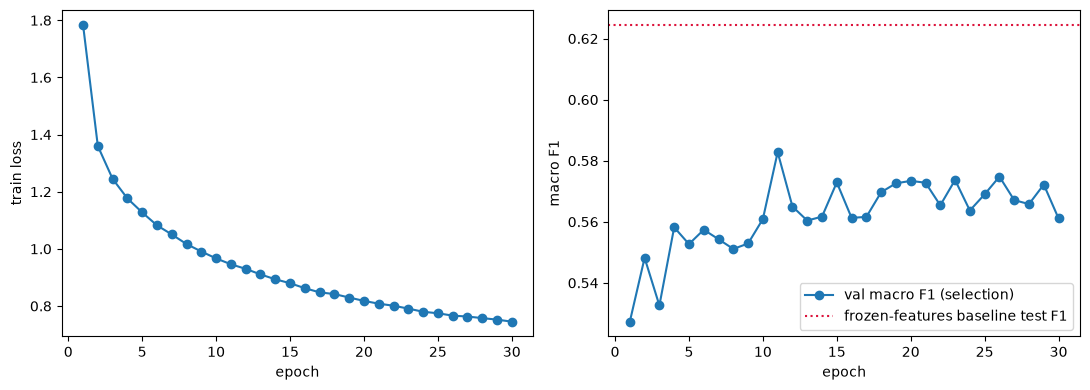

In [4]:
model_a, hist_a, row_a, m_a, gate_a, curve_a = run_arm("finetune_reg", "fc,layer4", 1e-4, 0.1)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(hist_a.epoch, hist_a.train_loss, "o-")
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("train loss")
ax[1].plot(hist_a.epoch, hist_a.val_macro_f1, "o-", label="val macro F1 (selection)")
ax[1].axhline(REF["frozen_logreg"], ls=":", color="crimson", label="frozen-features baseline test F1")
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("macro F1"); ax[1].legend()
plt.tight_layout(); plt.savefig(OUT / "armA_curves.png", dpi=120)
print(json.dumps(row_a, indent=2))

## Arm B — frozen backbone, head only, same augmentation and budget

If the backbone really is the problem on unseen camera sites, this arm should beat arm A while costing a
fraction of the compute. It also isolates one variable at a time against arm A: which parameters receive
gradients.

loaded resnet50-11ad3fa6.pth (318 tensors), head replaced


{'epoch': 1, 'train_loss': 1.86135, 'sec': 203.5, 'steps': 1127, 'val_macro_f1': 0.4363, 'val_accuracy': 0.5416}


{'epoch': 2, 'train_loss': 1.57499, 'sec': 200.7, 'steps': 1127, 'val_macro_f1': 0.466, 'val_accuracy': 0.5746}


{'epoch': 3, 'train_loss': 1.49244, 'sec': 201.3, 'steps': 1127, 'val_macro_f1': 0.4799, 'val_accuracy': 0.5931}


{'epoch': 4, 'train_loss': 1.44655, 'sec': 223.7, 'steps': 1127, 'val_macro_f1': 0.4954, 'val_accuracy': 0.6039}


{'epoch': 5, 'train_loss': 1.41597, 'sec': 211.5, 'steps': 1127, 'val_macro_f1': 0.4743, 'val_accuracy': 0.5919}


... (22 outputs left out)

{'epoch': 28, 'train_loss': 1.2844, 'sec': 140.8, 'steps': 1127, 'val_macro_f1': 0.4871, 'val_accuracy': 0.6048}


{'epoch': 29, 'train_loss': 1.27969, 'sec': 143.2, 'steps': 1127, 'val_macro_f1': 0.4861, 'val_accuracy': 0.604}


{'epoch': 30, 'train_loss': 1.2814, 'sec': 142.1, 'steps': 1127, 'val_macro_f1': 0.494, 'val_accuracy': 0.612}


{
  "model": "head_only_aug",
  "test_macro_f1": 0.548,
  "test_macro_f1_rich": 0.5937,
  "test_accuracy": 0.6937,
  "best_epoch": 4,
  "val_best": 0.4954,
  "epochs_run": 30,
  "gate_alerts": 60,
  "gate_false": 7,
  "gate_missed": 86,
  "gate_precision": 0.8833,
  "gate_recall": 0.3813,
  "perframe_alerts": 175,
  "perframe_recall": 0.8058,
  "unfrozen": "fc",
  "lr": 0.0003,
  "label_smoothing": 0.1,
  "trainable": 2,
  "train_wall_sec": 4952.2
}


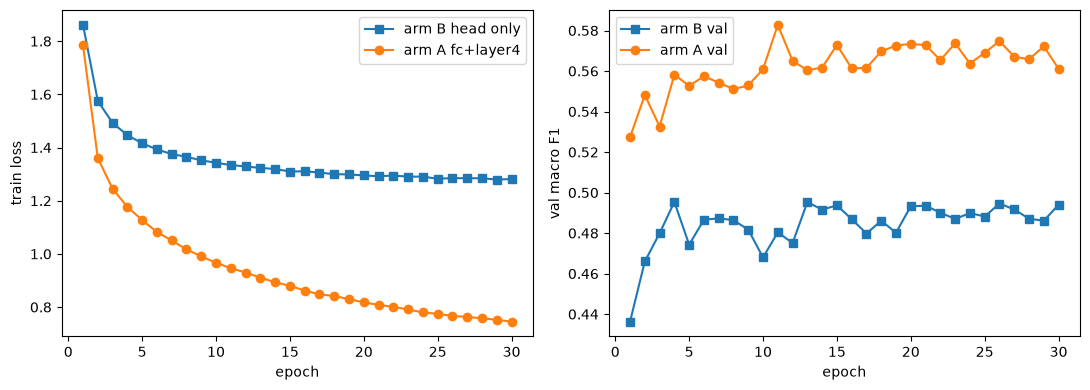

In [5]:
model_b, hist_b, row_b, m_b, gate_b, curve_b = run_arm("head_only_aug", "fc", 3e-4, 0.1)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(hist_b.epoch, hist_b.train_loss, "s-", label="arm B head only")
ax[0].plot(hist_a.epoch, hist_a.train_loss, "o-", label="arm A fc+layer4")
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("train loss"); ax[0].legend()
ax[1].plot(hist_b.epoch, hist_b.val_macro_f1, "s-", label="arm B val")
ax[1].plot(hist_a.epoch, hist_a.val_macro_f1, "o-", label="arm A val")
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("val macro F1"); ax[1].legend()
plt.tight_layout(); plt.savefig(OUT / "armA_vs_armB.png", dpi=120)
print(json.dumps(row_b, indent=2))

## Verdict

Compare against the frozen-feature logistic baseline (0.6245) on the same seed and split files. Whatever
wins here becomes the classifier that feeds the alert rule, and the gate columns show whether a better
classifier actually reduces missed alerts — the two are not the same claim.

In [6]:
summary = pd.DataFrame([{"model": "majority_class", "test_macro_f1": REF["majority"]},
                       {"model": "random", "test_macro_f1": REF["random"]},
                       {"model": "frozen_logreg_baseline", "test_macro_f1": REF["frozen_logreg"]},
                       {"model": "notebook02_finetune_8ep", "test_macro_f1": REF["notebook02_finetune"]},
                       row_a, row_b])
cols = [c for c in ("model", "val_best", "best_epoch", "epochs_run", "test_macro_f1",
                    "test_macro_f1_rich", "test_accuracy", "gate_false", "gate_missed",
                    "gate_precision", "gate_recall", "train_wall_sec") if c in summary]
summary = summary[cols]
summary["delta_vs_frozen_logreg"] = (summary.test_macro_f1 - REF["frozen_logreg"]).round(4)
best_arm = max([row_a, row_b], key=lambda r: r["val_best"])
print("selected on val:", best_arm["model"], "| its test macro F1", best_arm["test_macro_f1"],
      "| baseline 0.6245")
print("clears baseline:", best_arm["test_macro_f1"] > REF["frozen_logreg"])
summary.to_csv(OUT / "summary.csv", index=False)
summary.to_string(index=False)

selected on val: finetune_reg | its test macro F1 0.6403 | baseline 0.6245
clears baseline: True


'                  model  val_best  best_epoch  epochs_run  test_macro_f1  test_macro_f1_rich  test_accuracy  gate_false  gate_missed  gate_precision  gate_recall  train_wall_sec  delta_vs_frozen_logreg\n         majority_class       NaN         NaN         NaN         0.0201                 NaN            NaN         NaN          NaN             NaN          NaN             NaN                 -0.6044\n                 random       NaN         NaN         NaN         0.0645                 NaN            NaN         NaN          NaN             NaN          NaN             NaN                 -0.5600\n frozen_logreg_baseline       NaN         NaN         NaN         0.6245                 NaN            NaN         NaN          NaN             NaN          NaN             NaN                  0.0000\nnotebook02_finetune_8ep       NaN         NaN         NaN         0.6043                 NaN            NaN         NaN          NaN             NaN          NaN             NaN          

,rule,budget,true_alerts,false_alerts,precision,recall,arm
0,sequence_gate,50,45,5,0.9000,0.3237,A
1,sequence_gate,75,65,10,0.8667,0.4676,A
2,sequence_gate,100,78,22,0.7800,0.5612,A
3,sequence_gate,125,92,33,0.7360,0.6619,A
4,volume_ranked,50,44,6,0.8800,0.3165,A
5,volume_ranked,75,66,9,0.8800,0.4748,A
6,volume_ranked,100,79,21,0.7900,0.5683,A
7,volume_ranked,125,86,39,0.6880,0.6187,A
8,sequence_gate,50,44,6,0.8800,0.3165,B
9,sequence_gate,75,63,12,0.8400,0.4532,B


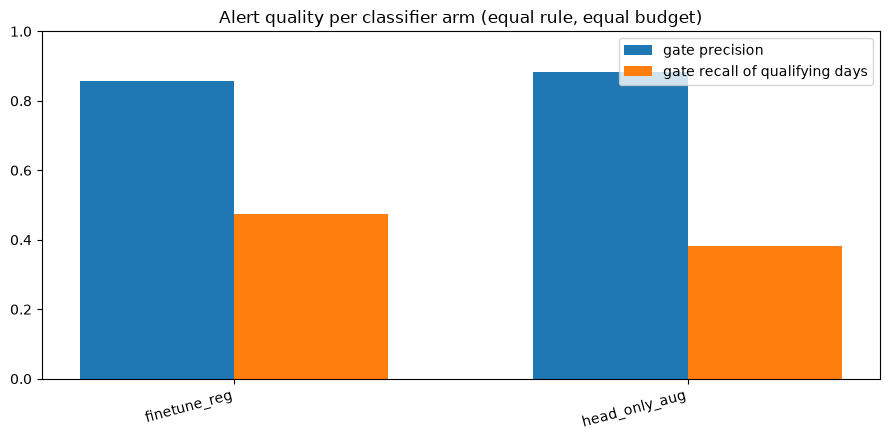

In [7]:
fig, ax = plt.subplots(figsize=(9, 4.5))
sub = summary.dropna(subset=["gate_recall"])
x = np.arange(len(sub))
ax.bar(x - 0.17, sub.gate_precision, 0.34, label="gate precision")
ax.bar(x + 0.17, sub.gate_recall, 0.34, label="gate recall of qualifying days")
ax.set_xticks(x); ax.set_xticklabels(sub.model, rotation=15, ha="right")
ax.set_ylim(0, 1); ax.legend(); ax.set_title("Alert quality per classifier arm (equal rule, equal budget)")
plt.tight_layout(); plt.savefig(OUT / "gate_by_arm.png", dpi=120)
pd.concat([curve_a.assign(arm="A"), curve_b.assign(arm="B")], ignore_index=True)

In [8]:
rows = []
for row, gate, curve, hist in ((row_a, gate_a, curve_a, hist_a), (row_b, gate_b, curve_b, hist_b)):
    r = {"run_utc": pd.Timestamp.now(tz="UTC").isoformat(),
         "experiment": "notebook07_longer_training", "seed": SEED, "splits": "data/splits/*.csv",
         "preprocessing": "RandomResizedCrop(0.5-1.0)+flip+jitter+grayscale+blur / resize256+center224",
         "loss": f"CrossEntropyLoss(label_smoothing={row['label_smoothing']}, class weights)",
         "optimizer": f"AdamW head lr={row['lr']} backbone lr/10 wd=1e-4",
         "epochs_max": EPOCHS, "patience": PATIENCE, "batch": BATCH,
         "metrics": row, "gate": gate, "budget_curve": curve.to_dict("records"),
         "history_last": hist.iloc[-1].to_dict(), "hardware": W.hardware_note()}
    with open(OUT / "experiment_log.jsonl", "a", encoding="utf-8") as fh:
        fh.write(json.dumps(r) + chr(10))
    rows.append(r["experiment"] + " " + row["model"])
print("logged:", rows)

logged: ['notebook07_longer_training finetune_reg', 'notebook07_longer_training head_only_aug']


## Honest reading rules for this notebook

* Selection uses **val** only. If arm A or B beats 0.6245 on test by less than about one standard error of
  this split size, the correct statement is "no better than the baseline", not "an improvement".
* `test_macro_f1_rich` drops classes with fewer than 50 test images; both numbers are reported because the
  all-class average is dominated by one class holding 2 test images.
* If both arms land below the logistic baseline, the Phase I model stays the baseline and the product's
  contribution is the alert rule plus calibration — recorded as a design decision with evidence, not a
  failure to hide.